# How does retrenchment and workload patterns relate to salary outcomes in Singapore over time?

***DONE BY: Ephraim  & Han qian***

# There are 3 datasets:
` df1 + df2 ` : Graduate employment survey(Salary of graduates based on their schools and universities)

`df3` : Sheet F1 [MOM DATASET] (Number of employees in each year by usual hours worked & gender)

` df4 `: Number of Permanent employees retrenched by industry and year

` df5 ` : Sheet F2 [MOM DATASET] (Number of employees in each year by gender & industry) 

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df1=pd.read_csv('(1) graduate employment survey modified.csv')
df2=pd.read_csv('(2) graduate employment survey modified .csv')
df3=pd.read_excel('LFR2023_SectionF.xlsx',sheet_name='F1', skiprows=5) #F1
df5=pd.read_excel('LFR2023_SectionF.xlsx',sheet_name='F2', skiprows=5) #F2
df4=pd.read_excel('mrsd_19_retrench_perm_by_ind_and_occ_grp (5).xlsx', sheet_name='2006-2025(SSIC2020)', skiprows=2)



In [17]:
# Noted that there are NAN (missing values) and also data with the literal 'na'. Convert all to NAN.
df2= df2.replace('na', np.nan)
# drop every column where theres NAN in all the rows (Chunk of unnamed rows)
df2 = df2.dropna(axis=1, how='all') 
df_merged = df1.merge(df2, on='Key', how='left') 
df_merged.info()
df_merged.isna().sum()
df_merged

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5135 entries, 0 to 5134
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   year                         5135 non-null   object
 1   university                   5135 non-null   object
 2   school                       5135 non-null   object
 3   degree                       5135 non-null   object
 4   Key                          5135 non-null   int64 
 5   employment_rate_overall      4657 non-null   object
 6   employment_rate_ft_perm      4657 non-null   object
 7   basic_monthly_mean           4657 non-null   object
 8   basic_monthly_median         4657 non-null   object
 9   gross_monthly_mean           4657 non-null   object
 10  gross_monthly_median         4657 non-null   object
 11  gross_mthly_25_percentile    4657 non-null   object
 12  gross_mthly_75_percentile    4657 non-null   object
 13  gross_monthly_mean.1         4657

,year,university,school,degree,Key,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,gross_mthly_25_percentile.1,gross_mthly_75_percentile.1
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1,97.4,96.1,3701,3200,3727,3350,2900,4000,3727,3350,2900,4000
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2,97.1,95.7,2850,2700,2938,2700,2700,2900,2938,2700,2700,2900
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3,90.9,85.7,3053,3000,3214,3000,2700,3500,3214,3000,2700,3500
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4,87.5,87.5,3557,3400,3615,3400,3000,4100,3615,3400,3000,4100
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5,95.3,95.3,3494,3500,3536,3500,3100,3816,3536,3500,3100,3816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5130,2012,Singapore Management University,School of Information Systems (4-year programm...,Information Systems Management (4-years progra...,5131,100,90.9,378.6,372.5,386.2,380,350,400,386.2,380,350,400
5131,2012,Singapore Management University,School of Social Sciences (4-year programme) *,Social Sciences (4-years programme),5132,86.5,79.8,312.2,300,315,300,260,332,315,300,260,332
5132,2012,Singapore Management University,School of Social Sciences (4-year programme) *,Social Sciences (4-years programme) Cum Laude ...,5133,87.5,83.3,325.1,320,326.7,320,280,378.1,326.7,320,280,378.1
5133,2012,Singapore Management University,School of Law (4-year programme) *,Law (4-years programme) #,5134,100,100,502.3,480,524.6,500,450,600,524.6,500,450,600


In [18]:
df_merged = df_merged.dropna(subset=['basic_monthly_mean']) 
# no specific reason to use basic_monthly_mean, as nan values are common across all df2 columns
salary_cols = df_merged.columns[5:]   

# Every column after index 5 is a integer val, hence we convert to float
df_merged[salary_cols] = df_merged[salary_cols].apply(pd.to_numeric, errors='coerce')
# There are values where the value is not a number, hence we drop these
df_merged = df_merged.dropna(subset=salary_cols, how='all')


# final check
df_merged.info()
df_merged.isna().sum()


<class 'pandas.core.frame.DataFrame'>
Index: 4656 entries, 0 to 5134
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   year                         4656 non-null   object 
 1   university                   4656 non-null   object 
 2   school                       4656 non-null   object 
 3   degree                       4656 non-null   object 
 4   Key                          4656 non-null   int64  
 5   employment_rate_overall      4656 non-null   float64
 6   employment_rate_ft_perm      4656 non-null   float64
 7   basic_monthly_mean           4656 non-null   float64
 8   basic_monthly_median         4656 non-null   float64
 9   gross_monthly_mean           4656 non-null   float64
 10  gross_monthly_median         4656 non-null   float64
 11  gross_mthly_25_percentile    4656 non-null   float64
 12  gross_mthly_75_percentile    4656 non-null   float64
 13  gross_monthly_mean.1   

<tmp>\ipykernel_23788\2354422059.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_merged[salary_cols] = df_merged[salary_cols].apply(pd.to_numeric, errors='coerce')


year                           0
university                     0
school                         0
degree                         0
Key                            0
employment_rate_overall        0
employment_rate_ft_perm        0
basic_monthly_mean             0
basic_monthly_median           0
gross_monthly_mean             0
gross_monthly_median           0
gross_mthly_25_percentile      0
gross_mthly_75_percentile      0
gross_monthly_mean.1           0
gross_monthly_median.1         0
gross_mthly_25_percentile.1    0
gross_mthly_75_percentile.1    0
dtype: int64

In [19]:
df3.drop(df3.index[-2:], inplace=True) #remove source and nan at end

# Make first row into column head(years)

df3.columns = df3.iloc[0] 
df3 = df3.iloc[1:].reset_index(drop=True)

df3.columns.values[0] = 'employcat'
df3.columns.values[1] = 'hours_worked'
df3['employcat']=df3['employcat'].ffill()
df3melt=df3.melt(id_vars=['employcat','hours_worked'],var_name='year',value_name='employees')

df3melt['employees'] = df3melt['employees'] * 1000
df3melt['employees'] = df3melt['employees'].astype(int)
df3melt['year'] = df3melt['year'].astype(int)


display(df3melt)

df3melt.info()




,employcat,hours_worked,year,employees
0,Total,Total,2013,2004600
1,Total,Below 15 Hours,2013,40300
2,Total,15 - 29 Hours,2013,108700
3,Total,30 - 34 Hours,2013,53000
4,Total,35 - 39 Hours,2013,57000
...,...,...,...,...
358,Female,45 - 49 Hours,2023,132400
359,Female,50 - 54 Hours,2023,60300
360,Female,55 - 59 Hours,2023,17100
361,Female,60 Hours & Over,2023,43600


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 363 entries, 0 to 362
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   employcat     363 non-null    object
 1   hours_worked  363 non-null    object
 2   year          363 non-null    int64 
 3   employees     363 non-null    int64 
dtypes: int64(2), object(2)
memory usage: 11.5+ KB


In [20]:


# Make all year into column headers
new_header = df4.loc[0].tolist()
df4.columns = new_header

# remove unneccessary rows in head and tail
df4.drop(df4.index[0], inplace=True)
df4.drop(df4.index[-7:], inplace=True)

# remove quarterly data (irrelevant for us)
df4.drop(['1Q','2Q','3Q','4Q'], axis=1, inplace=True)
df4=df4.drop(columns=[2025]) #This doesnt have any meaningful data

# rename 2nd column to industry, remove SSIC column
df4.columns.values[1] = 'industry'
df4.drop(df4.columns[0], axis=1, inplace=True)


# drop rows where all years are NA (these rows are useless)
df4.dropna(subset=df4.columns[2:], how='all', inplace=True)

# according to df- all '-' insignificant
df4 = df4.replace('-', 0)


df4


<tmp>\ipykernel_23788\3998500369.py:22: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df4 = df4.replace('-', 0)


,industry,2006,2007,2008,2009.0,2010,2011,2012,2013,2014,2015.0,2016,2017.0,2018,2019.0,2020,2021.0,2022,2023,2024
1,TOTAL,12600,7680,13920,20160.0,7740,8350,9670,10540,10910,13440.0,16810,12880.0,9610,9810.0,22540,7480.0,5560,13830,12570
3,MANUFACTURING,8720,5250,8390,11920.0,3780,3920,3710,4830,3350,4790.0,5620,3330.0,2280,2580.0,5000,1640.0,1500,3270,2660
4,"Food, Beverages & Tobacco",140,120,50,10.0,20,10,10,20,120,80.0,290,190.0,150,40.0,310,100.0,30,120,60
5,Paper/Rubber/Plastic Products & Printing,240,420,830,700.0,470,640,540,360,150,560.0,360,480.0,160,160.0,230,70.0,30,120,370
6,"Petroleum, Chemical & Pharmaceutical Products",110,50,190,220.0,160,320,230,210,160,310.0,360,290.0,170,190.0,150,450.0,200,230,510
7,"Fabricated Metal Products, Machinery & Equipment",1100,970,1520,2370.0,940,420,670,650,1070,1510.0,2240,800.0,780,650.0,1190,140.0,450,470,780
8,"Electronic, Computer & Optical Products",6570,2210,4150,6110.0,1690,2010,1730,2280,1280,1630.0,1670,920.0,570,1080.0,790,680.0,630,2010,760
9,Transport Equipment,100,90,500,1080.0,230,60,40,150,280,470.0,450,550.0,260,110.0,1650,130.0,80,110,40
10,Other Manufacturing Industries,460,1400,1150,1430.0,270,460,510,1170,300,240.0,260,110.0,190,340.0,680,70.0,80,200,140
11,CONSTRUCTION,390,20,250,450.0,550,470,450,710,990,770.0,870,1190.0,800,500.0,750,210.0,110,450,380


In [21]:
df4=df4.melt(id_vars=['industry'],var_name='year',value_name='employees')
# melt to convert wide dataframe to long
df4['year'] = df4['year'].astype(int)
# convert all year to int
df4['employees'] = df4['employees'].astype(int)
# convert all employees to int


display(df4)
df4.info()

,industry,year,employees
0,TOTAL,2006,12600
1,MANUFACTURING,2006,8720
2,"Food, Beverages & Tobacco",2006,140
3,Paper/Rubber/Plastic Products & Printing,2006,240
4,"Petroleum, Chemical & Pharmaceutical Products",2006,110
...,...,...,...
869,"Other Community, Social & Personal Services",2024,50
870,OTHERS*,2024,60
871,"Professionals, Managers, Executives & Technici...",2024,9990
872,"Clerical, Sales and Services Workers",2024,1060


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 874 entries, 0 to 873
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   industry   874 non-null    object
 1   year       874 non-null    int64 
 2   employees  874 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 20.6+ KB


# DF5 CLEANING

In [22]:
df5.drop(df5.index[-5:], inplace=True) #remove source and nan at end

# Make first row into column head(years)
df5.columns = df5.iloc[0] 
df5 = df5.iloc[1:].reset_index(drop=True)

df5.columns.values[0] = 'employcat'
df5.columns.values[1] = 'hours_worked'
df5['employcat']=df5['employcat'].ffill()
df5=df5.melt(id_vars=['employcat','hours_worked'],var_name='industry',value_name='employees')
df5=df5.drop(df5[df5['industry']=='Others'].index)

df5['employees'] = df5['employees'] * 1000
df5['employees'] = df5['employees'].astype(int)




df5

,employcat,hours_worked,industry,employees
0,Total,Total,Total,2312200
1,Total,Below 15 Hours,Total,51200
2,Total,15 - 29 Hours,Total,134900
3,Total,30 - 34 Hours,Total,64000
4,Total,35 - 39 Hours,Total,124600
...,...,...,...,...
292,Female,45 - 49 Hours,"Cleaners, Labourers & Related Workers",8700
293,Female,50 - 54 Hours,"Cleaners, Labourers & Related Workers",2800
294,Female,55 - 59 Hours,"Cleaners, Labourers & Related Workers",1000
295,Female,60 Hours & Over,"Cleaners, Labourers & Related Workers",1600


# EVERYTHING IS CLEANED

* How have retrenchment levels in Singapore changed over time, and what do they indicate about labour market stress?
  - Retrenchment levels are generally fluctuating, and have a general increase, especially across Manufacturing and Services sectors.
  - This tells that these industries are more prone to retrenchment
* How have workload patterns (especially long working hours) changed over time, and are there differences by gender?
  - Number of employees working overtime decreases across the years, and generally, lesser female employees work overtime than male employees
* How have graduate salary outcomes evolved over the same period?
* Do periods of higher labour market stress and heavier workloads coincide with changes in graduate salary outcomes?

In [23]:
# DF_MERGED DATA MAPPING


df4sect = df4[(df4['industry'].str.isupper()) & (df4['industry'] != 'TOTAL') & (df4['industry'] != 'OTHERS*')] 
sectorlist = df4sect['industry'].unique()

# List of keywords relating to each sector
sectorkey = {
    'INFORMATION AND COMMUNICATIONS': [
        'comput', 'software', 'data', 'infocomm', 'digital', 'it', 'communication studies', 'systems'
    ],
    'FINANCIAL AND INSURANCE SERVICES': [
        'account', 'finance', 'banking', 'insurance', 'actuarial', 'economics'
    ],
    'REAL ESTATE SERVICES': [
        'real estate', 'property'
    ],
    'MANUFACTURING': [
        'engineering', 'manufacture', 'mechanical', 'electrical', 'aerospace', 'industrial', 'applied science'
    ],
    'COMMUNITY, SOCIAL AND PERSONAL SERVICES': [
        'medicine', 'nursing', 'health', 'pharmacy', 'social', 'psychology', 
        'sociology', 'education', 'sports', 'chinese', 'english', 'linguistic', 'arts', 'dental'
    ],
    'CONSTRUCTION': [
        'civil', 'construction', 'built environment'
    ],
    'TRANSPORTATION AND STORAGE': [
        'logistics', 'supply chain', 'maritime', 'aviation', 'transport'
    ],
    'SERVICES': [
        'business', 'management', 'administration', 'marketing', 'hr', 'human resource'
    ],
    'PROFESSIONAL SERVICES': [
        'law', 'legal', 'architecture', 'design', 'consulting', 'bio', 'chem', 'math', 'science', 'physics'
    ]
}


def map(degree):
    degree = degree.lower()
    for sector, keywords in sectorkey.items():
        for kw in keywords:
            if kw in degree:
                return sector

    return 'OTHERS'

df_merged['Sector'] = df_merged['degree'].apply(map)

df_merged=df_merged.drop(columns=['school']) 
# not safe to use school, as it still has na values. we drop it because it is irrelevant to us


print(df_merged['Sector'].value_counts())
df_merged.head()


Sector
INFORMATION AND COMMUNICATIONS             1610
MANUFACTURING                               836
COMMUNITY, SOCIAL AND PERSONAL SERVICES     773
PROFESSIONAL SERVICES                       498
FINANCIAL AND INSURANCE SERVICES            447
SERVICES                                    296
OTHERS                                      140
REAL ESTATE SERVICES                         40
TRANSPORTATION AND STORAGE                   16
Name: count, dtype: int64


,year,university,degree,Key,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,gross_mthly_25_percentile.1,gross_mthly_75_percentile.1,Sector
0,2013,Nanyang Technological University,Accountancy and Business,1,97.4,96.1,3701.0,3200.0,3727.0,3350.0,2900.0,4000.0,3727.0,3350.0,2900.0,4000.0,FINANCIAL AND INSURANCE SERVICES
1,2013,Nanyang Technological University,Accountancy (3-yr direct Honours Programme),2,97.1,95.7,2850.0,2700.0,2938.0,2700.0,2700.0,2900.0,2938.0,2700.0,2700.0,2900.0,FINANCIAL AND INSURANCE SERVICES
2,2013,Nanyang Technological University,Business (3-yr direct Honours Programme),3,90.9,85.7,3053.0,3000.0,3214.0,3000.0,2700.0,3500.0,3214.0,3000.0,2700.0,3500.0,SERVICES
3,2013,Nanyang Technological University,Business and Computing,4,87.5,87.5,3557.0,3400.0,3615.0,3400.0,3000.0,4100.0,3615.0,3400.0,3000.0,4100.0,INFORMATION AND COMMUNICATIONS
4,2013,Nanyang Technological University,Aerospace Engineering,5,95.3,95.3,3494.0,3500.0,3536.0,3500.0,3100.0,3816.0,3536.0,3500.0,3100.0,3816.0,MANUFACTURING


***GRAPH 1***

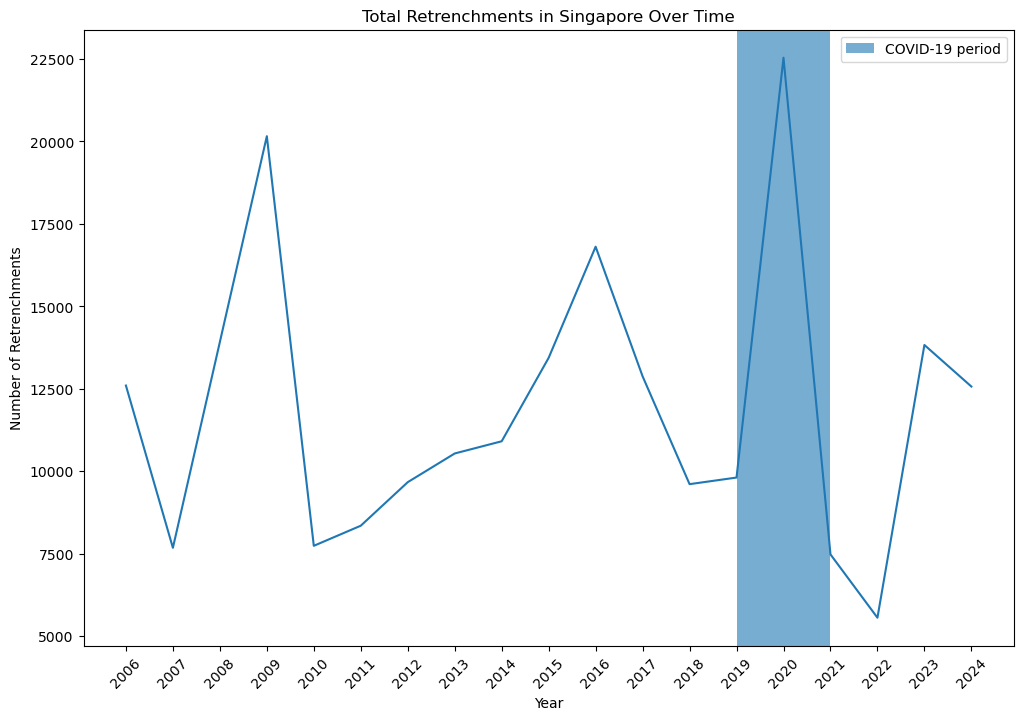

In [24]:
# Graph1: Total retrenchment over time

ret_total = df4[df4['industry']=='TOTAL']
plt.figure(figsize=(12, 8))

plt.plot(ret_total['year'], ret_total['employees'])

# Shade COVID-19 period , alpha is transparency
plt.axvspan(2019, 2021, alpha=0.6, label='COVID-19 period')

# Labels and title
plt.title('Total Retrenchments in Singapore Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Retrenchments')
plt.xticks(ret_total['year'])
plt.xticks(ret_total['year'], rotation=45)
plt.legend()





# Interpretation:
*  As seen in the graph, the retrenchment rate fluctuates, for example based on social situations like covid 19. Even though there is an overall increasing trend, individual sectors may affect the retrenchment rates.
* Hence, we analyse retrenchment rate based on sector

***GRAPH 2***


<Figure size 1600x1000 with 0 Axes>

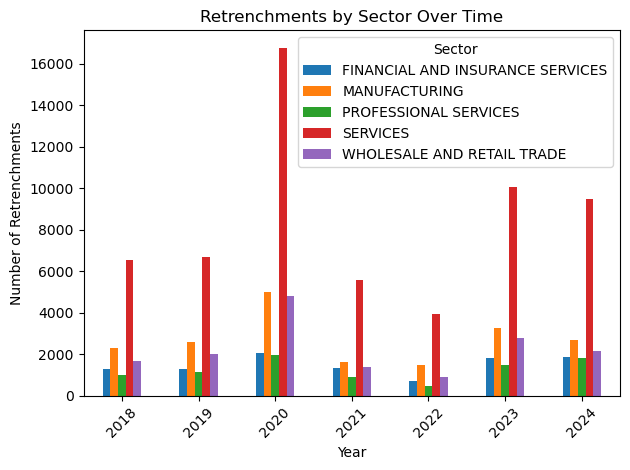

In [25]:
# Graph2: Retrenchment Split by sectors

df4sect = df4[(df4['industry'].str.isupper()) & (df4['industry'] != 'TOTAL')] 
top5sects = (df4sect.groupby('industry')['employees'].sum().sort_values(ascending=False).head(5).index)

df4sect = df4sect[df4sect['industry'].isin(top5sects)]
df4sect = df4sect[df4sect['year'].between(2018, 2024)]

stack_data = (
    df4sect
    .groupby(['year', 'industry'])['employees']
    .sum()
    .unstack()
    .sort_index()
)

plt.figure(figsize=(16, 10))
stack_data.plot(kind='bar')

plt.title('Retrenchments by Sector Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Retrenchments')
plt.xticks(rotation=45)
plt.legend(title='Sector')

plt.tight_layout()
plt.show()


# Interpretation:
* The general trend (In the last 5 years 2018-2024) is that Services and Manufacturing sector consists of majority retrenchment rate.
* There is higher risk for people working in Services and Manufacturing sectors.

***Graph 3***

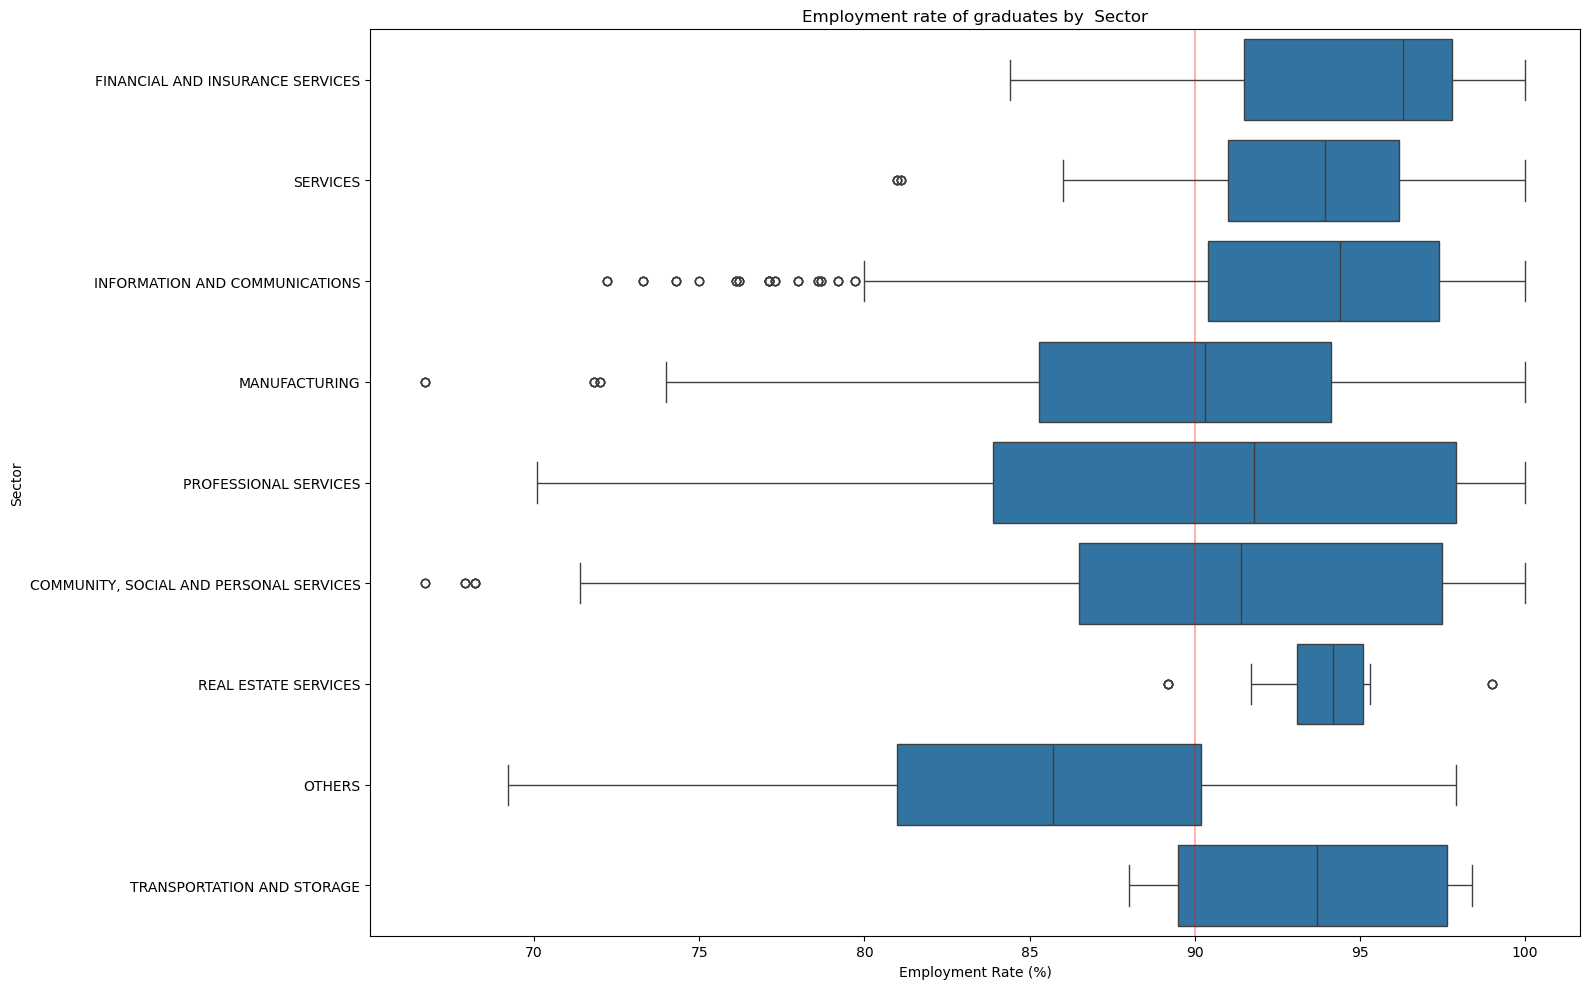

In [26]:
# Graph 3 : boxplot of employment rate by sector

df_plot = df_merged.dropna(subset=['employment_rate_overall', 'Sector'])

plt.figure(figsize=(16, 10))

sns.boxplot(
    data=df_plot, 
    x='employment_rate_overall', 
    y='Sector', 
)


plt.axvline(90, color='r', linestyle='-', alpha=0.3)
plt.title('Employment rate of graduates by  Sector')
plt.xlabel('Employment Rate (%)')

plt.tight_layout()
plt.show()

# Interpretation
* Median employment rate is highest for graduates from Financial and Insurance services, while lowest for graduates from Manufacturing (excluding other degrees)
    - This tells us that graduates from Financial and Insurance services have the highest average chance of getting employment, while graduates from manufacturing has the lowest average chance of getting employment
* The distribution of employment rate is highest for graduates from professional services, while lowest for real estate services graduates.
    - Despite the relatively high median employment rate, graduates from professional services do not always get employed.
    - Graduates from real estate services have generally a high chance of getting employment.



***GRAPH 4***

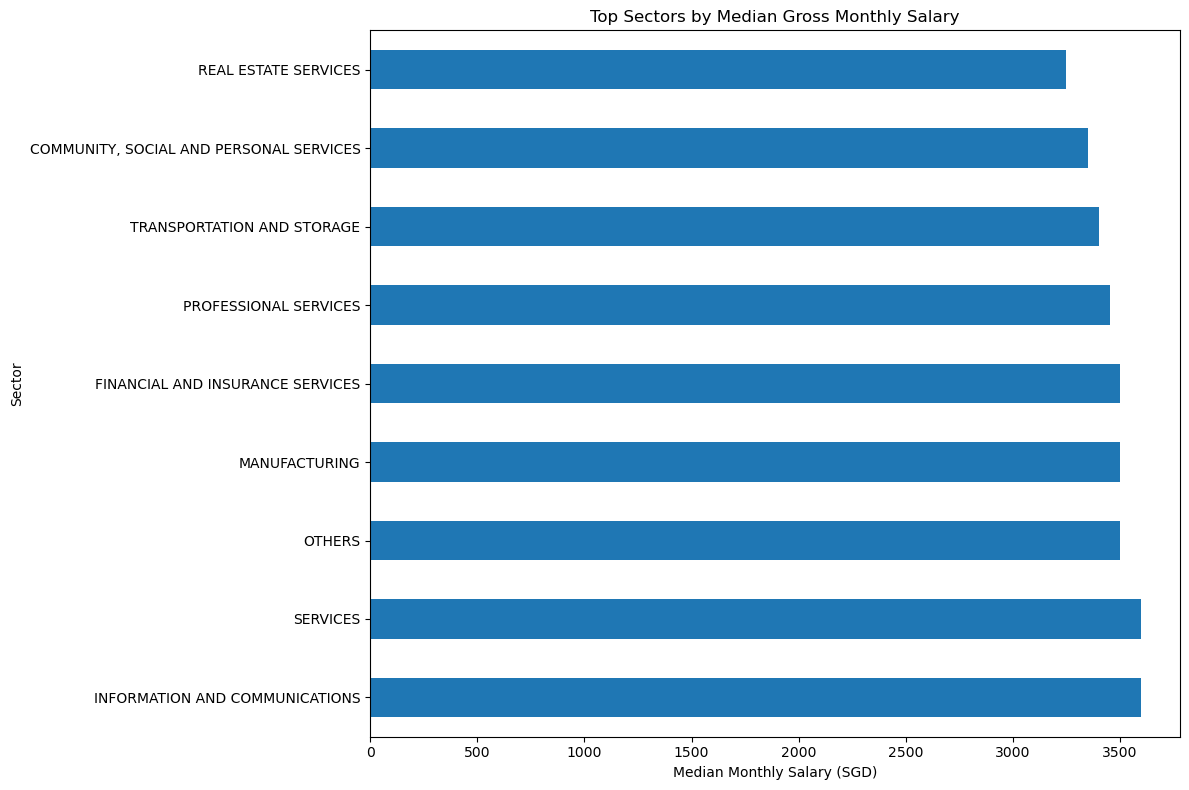

In [27]:
#Graph 4: (median gross monthly median by sector)
top_sectors = df_merged.groupby('Sector')['gross_monthly_median'].median().sort_values(ascending=False).head(10)

# Plotting
plt.figure(figsize=(12, 8))
top_sectors.plot(kind='barh')

# Formatting
plt.title('Top Sectors by Median Gross Monthly Salary')
plt.xlabel('Median Monthly Salary (SGD)')

plt.tight_layout()
plt.show()


# Interpretation
* Information and Communications offers the highest median monthly salary while Real Estate Services records the lowest.
* However, the overall variation across sectors is relatively small, indicating that median wages are fairly consistent across industries.

***Graph 5***

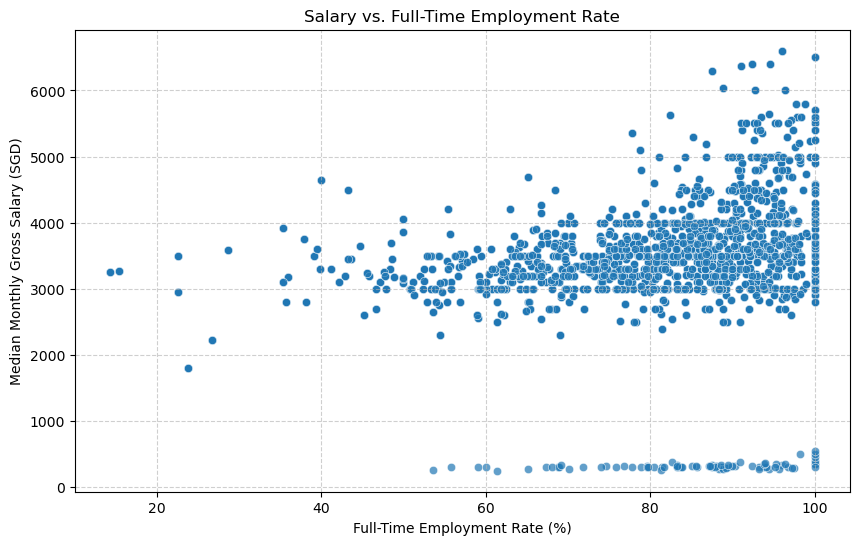

In [28]:
plt.figure(figsize=(10, 6))


sns.scatterplot(data=df_merged, x='employment_rate_ft_perm',y='gross_monthly_median', alpha=0.7)

plt.title('Salary vs. Full-Time Employment Rate')
plt.xlabel('Full-Time Employment Rate (%)')
plt.ylabel('Median Monthly Gross Salary (SGD)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Interpretation:
* Most jobs with high employment rates are also paid well
* There are still outliers, but this is the general trend (this can be affected by sectors and job roles)

***GRAPH 6***

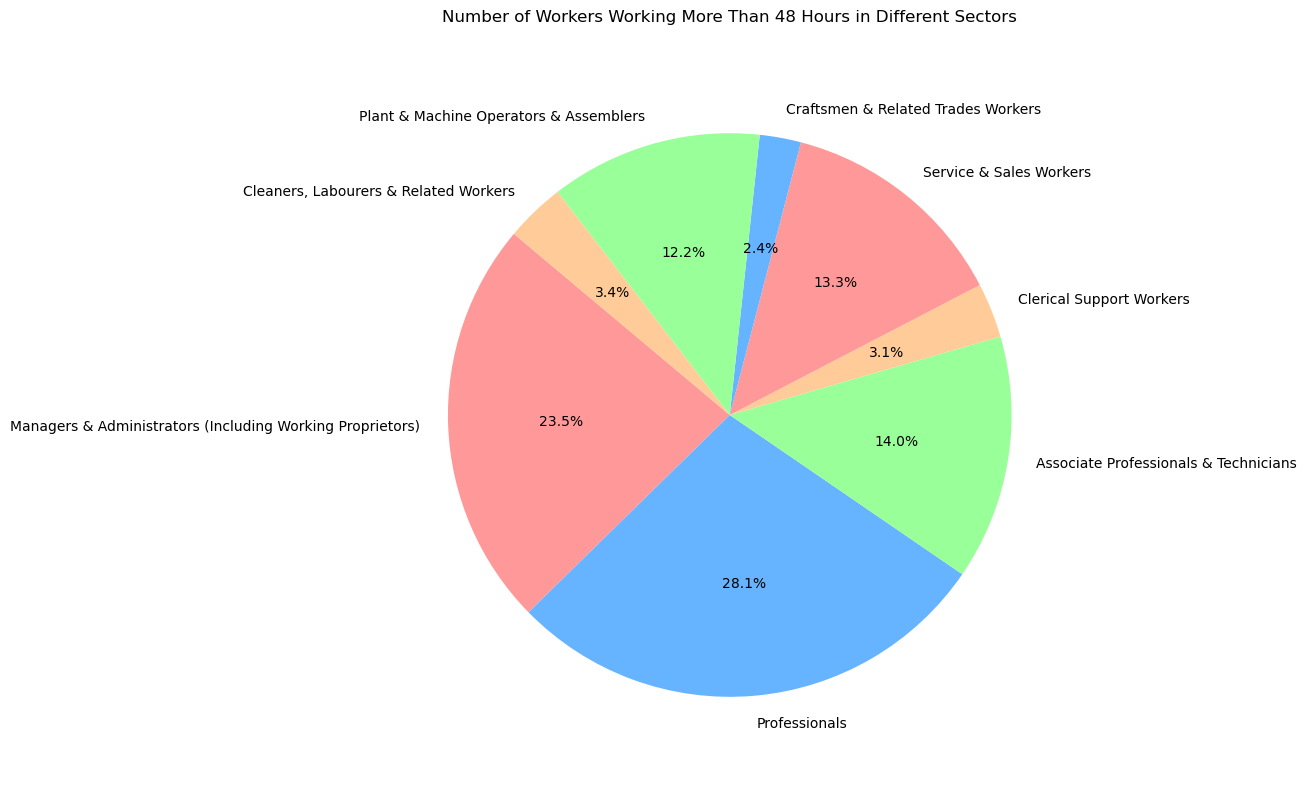

In [29]:
df5
plt.figure(figsize=(8,10))
workers=df5[(df5['hours_worked']=='More Than 48 Hours') & (df5['employcat']=='Total')&(df5['industry'] != 'Total')]
count=workers['employees']
label=workers['industry'].value_counts()

plt.pie(count, labels=label.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')

# Title for the chart
plt.title('Number of Workers Working More Than 48 Hours in Different Sectors')

# Display the pie chart
plt.show()


# Interpretation:
* Professionals usually are more prone to working overtime, while craftsmen and related trade workers, as well as labour related jobs require less overtime work
* Overtime work is usually demanded by jobs in higher levels

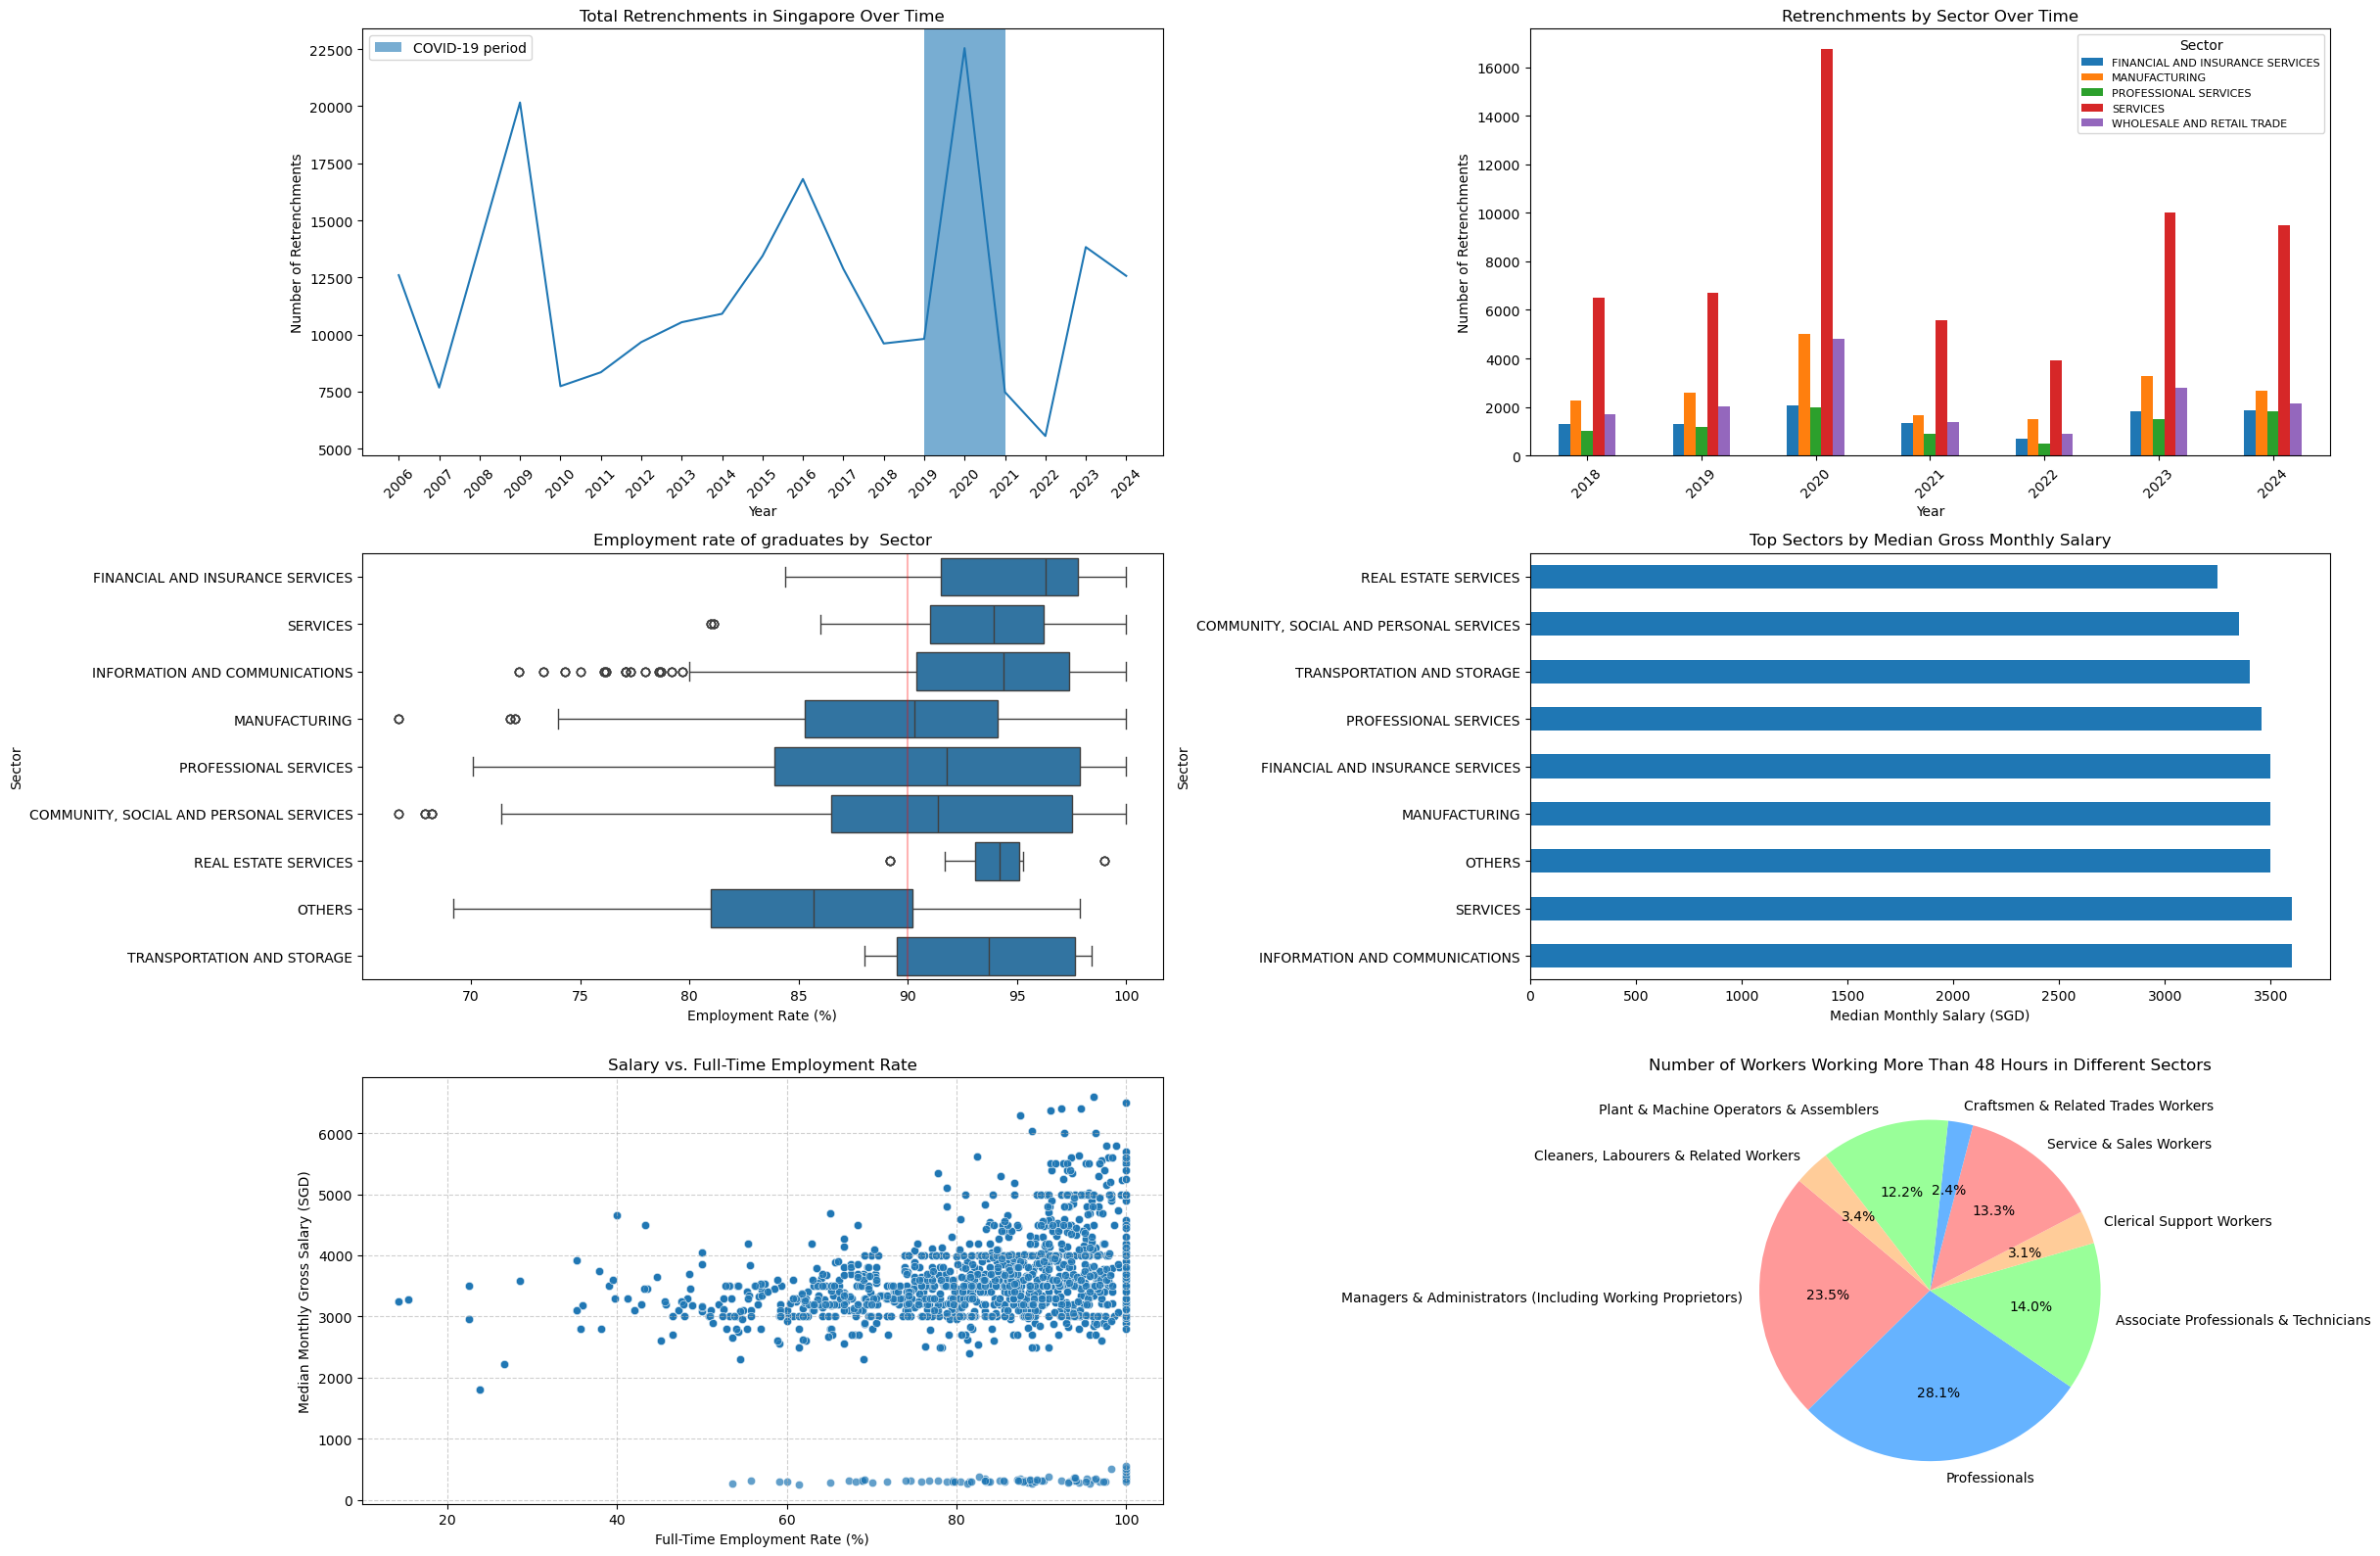

In [30]:
fig, axes = plt.subplots(3, 2, figsize=(24,16))

# Define df_plot at the start
df_plot = df_merged.dropna(subset=['employment_rate_overall', 'Sector'])

# Graph1: Total retrenchment over time
ax1 = axes[0, 0]

ret_total = df4[df4['industry']=='TOTAL']
ax1.plot(ret_total['year'], ret_total['employees'])

# Shade COVID-19 period , alpha is transparency
ax1.axvspan(2019, 2021, alpha=0.6, label='COVID-19 period')

# Labels and title
ax1.set_title('Total Retrenchments in Singapore Over Time')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Retrenchments')
ax1.set_xticks(ret_total['year'])
ax1.set_xticklabels(ret_total['year'], rotation=45)
ax1.legend()




# Interpretation: As seen in the graph, the retrenchment rate fluctuates, for example based on social situations like covid 19. Even though there is an overall increasing trend, individual sectors may affect the retrenchment rates.



# Graph 2:
ax2 = axes[0, 1]
# Graph2: Retrenchment Split by sectors

df4sect = df4[(df4['industry'].str.isupper()) & (df4['industry'] != 'TOTAL')] 
# Get all sectors (since sectors is uppercase)

top5sects = (df4sect.groupby('industry')['employees'].sum().sort_values(ascending=False).head(5).index)

# get df, where years are between 2018 and 2014, and industry only includes top 5 sectors with highest retrenchment
df4sect = df4sect[df4sect['industry'].isin(top5sects)]
df4sect = df4sect[df4sect['year'].between(2018, 2024)]


stack_data = (
    df4sect
    .groupby(['year', 'industry'])['employees']
    .sum()
    .unstack()
    .sort_index()
)


stack_data.plot(kind='bar',ax=ax2)

ax2.set_title('Retrenchments by Sector Over Time')
ax2.set_xlabel('Year')
ax2.set_ylabel('Number of Retrenchments')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Sector', fontsize=8)




# graph 3: Employment rate by sector

ax3 = axes[1,0]

# Create the Boxplot
sns.boxplot(
    data=df_plot, 
    x='employment_rate_overall', 
    y='Sector',
    ax=ax3
)

ax3.axvline(90, color='r', linestyle='-', alpha=0.3)
ax3.set_title('Employment rate of graduates by  Sector')
ax3.set_xlabel('Employment Rate (%)')

# Graph 4: median gross monthly salary by sector
ax4 = axes[1, 1]
top_sectors = df_merged.groupby('Sector')['gross_monthly_median'].median().sort_values(ascending=False).head(10)
top_sectors.plot(kind='barh', ax=ax4)
ax4.set_title('Top Sectors by Median Gross Monthly Salary')
ax4.set_xlabel('Median Monthly Salary (SGD)')

# Graph 5: Salary vs. Full-Time Employment Rate
ax5 = axes[2, 0]
sns.scatterplot(data=df_merged, x='employment_rate_ft_perm', y='gross_monthly_median', alpha=0.7, ax=ax5)
ax5.set_title('Salary vs. Full-Time Employment Rate')
ax5.set_xlabel('Full-Time Employment Rate (%)')
ax5.set_ylabel('Median Monthly Gross Salary (SGD)')
ax5.grid(True, linestyle='--', alpha=0.6)

# Graph 6: Workers working more than 48 hours
ax6 = axes[2, 1]
workers = df5[(df5['hours_worked']=='More Than 48 Hours') & (df5['employcat']=='Total') & (df5['industry'] != 'Total')]
count = workers['employees']
labels = workers['industry']
ax6.pie(count, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
ax6.set_title('Number of Workers Working More Than 48 Hours in Different Sectors')

fig.tight_layout()
plt.show()

# Final Conclusion
* While retrenchment and workload patterns vary by sector, the strongest predictor of salary is job security rather than working hours. While deciding a job area to work on,choose sectors with low retrenchment rates and high graduate employment for better salary. 
* The sectors with highest retrenchment rates are: 
    - Services 
    - Manufacturing
    - Wholesale & Retail Trade
    - Financial & Insurance Services
    - Professional Services

* Best sectors to be in are: 
    1. Financial & Insurance Services
    Highest graduate employment rate (>95%)
    High median salary (~$3,500+)
    Average retrenchment rates
    
    2. Professional Services
    High graduate employment rate (>90%)
    High median salary (~$3,500)
    Lower retrenchment risk
    - However these have high overtime


    3. Information & Communications
    Highest salary levels (~$3,600)
    Growing sector
    Moderate employment rates
    Higher retrenchment
    - However these have high overtime
